# Glucotrack Clustering — Member 1
## Clustering Track

**Dataset:** Diabetes Prediction Dataset - 100,000 records, 9 columns  
**Ground-truth label:** `diabetes` - used only for post-clustering interpretation  
**Algorithms:** K-Means and Agglomerative Hierarchical Clustering

This notebook follows the same structured style as the Regression notebook: numbered sections, clearly labelled code cells, printed checkpoints, EDA, preprocessing, model fitting, evaluation, plots, and observations.

**Important:** The `diabetes` column is excluded from all clustering features and model fitting. It is used only after clustering for interpretation and external validation.

**Member 1 scope:** dataset inspection, EDA, preprocessing, K-Means, and K-Means evaluation. Commit this first section to the shared `notebooks/clustering.ipynb` before your teammate continues.

## 1. Setup and Dataset Understanding

### 1.1 Import libraries

The notebook uses pandas and NumPy for data handling, Matplotlib and Seaborn for plots, and scikit-learn/SciPy for clustering, evaluation, dimensionality reduction, and dendrograms.

In [10]:
# CELL 1: Setup & Imports

import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


### 1.2 Load the dataset

The CSV is read from `../data/`, so the notebook runs from the project's `notebooks/` folder without changing paths.

In [11]:
# CELL 2: Load Dataset

DATA_PATH = "../data/diabetes_prediction_dataset.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Place diabetes_prediction_dataset.csv inside the project's data folder."
    )

df = pd.read_csv(DATA_PATH)

print("=" * 60)
print("DATASET LOADING")
print("=" * 60)
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Loaded from: {DATA_PATH}")
display(df.head())

DATASET LOADING
Dataset shape: 100,000 rows × 9 columns
Loaded from: ../data/diabetes_prediction_dataset.csv


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


### 1.3 Dataset structure

Inspect the column names and data types before deciding how to preprocess the features.

In [12]:
# CELL 3: Dataset Structure

print("=" * 60)
print("DATASET STRUCTURE")
print("=" * 60)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nDataset information:")
df.info()

DATASET STRUCTURE

Column names:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Data types:


,Data Type
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


### 1.4 Missing values and duplicates

Measure missing values and duplicate records before making any preprocessing decisions.

In [13]:
# CELL 4: Missing Value Analysis

missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing (%)": (df.isnull().mean() * 100).round(2)
})

print("=" * 60)
print("MISSING VALUE ANALYSIS")
print("=" * 60)
display(missing)

MISSING VALUE ANALYSIS


,Missing Values,Missing (%)
gender,0,0.0
age,0,0.0
hypertension,0,0.0
heart_disease,0,0.0
smoking_history,0,0.0
bmi,0,0.0
HbA1c_level,0,0.0
blood_glucose_level,0,0.0
diabetes,0,0.0


In [14]:
# CELL 5: Duplicate Record Analysis

duplicate_count = df.duplicated().sum()

print("=" * 60)
print("DUPLICATE RECORD ANALYSIS")
print("=" * 60)
print(f"Duplicate rows: {duplicate_count:,}")
print(f"Duplicate percentage: {duplicate_count / len(df) * 100:.2f}%")

DUPLICATE RECORD ANALYSIS
Duplicate rows: 3,854
Duplicate percentage: 3.85%


### 1.5 Descriptive statistics

Review the distributions and scales of numeric columns.

In [15]:
# CELL 6: Descriptive Statistics

print("=" * 60)
print("DESCRIPTIVE STATISTICS")
print("=" * 60)
display(df.describe(include="all").T)

DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,100000,3,Female,58552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,41.885856,22.51684,0.08,24.0,43.0,60.0,80.0
hypertension,100000.0,NaN,NaN,NaN,0.07485,0.26315,0.0,0.0,0.0,0.0,1.0
heart_disease,100000.0,NaN,NaN,NaN,0.03942,0.194593,0.0,0.0,0.0,0.0,1.0
smoking_history,100000,6,No Info,35816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,100000.0,NaN,NaN,NaN,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,NaN,NaN,NaN,5.527507,1.070672,3.5,4.8,5.8,6.2,9.0
blood_glucose_level,100000.0,NaN,NaN,NaN,138.05806,40.708136,80.0,100.0,140.0,159.0,300.0
diabetes,100000.0,NaN,NaN,NaN,0.085,0.278883,0.0,0.0,0.0,0.0,1.0


### Observation - 1

After running the cells above, note the dataset size, any missing values, duplicates, and unusual value ranges. The notebook preserves the original rows for clustering; duplicate removal is not automatic because it changes the dataset population.

---

# 2. Exploratory Data Analysis

EDA is used to understand the dataset before clustering. The `diabetes` label is visualized only as a reference; it will not be included in the clustering input.

Ground-truth label counts (reference only):


,Count
diabetes,
0,91500
1,8500


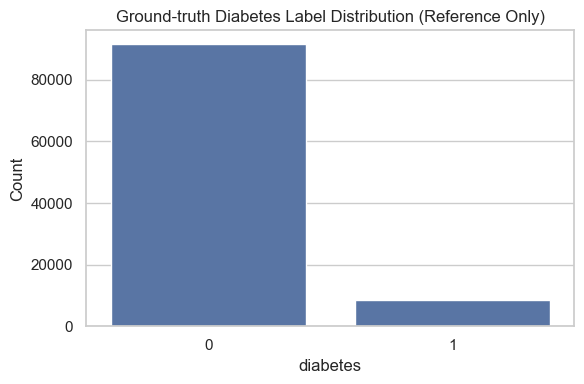

In [16]:
# CELL 7: Target Distribution (Reference Only)

if "diabetes" not in df.columns:
    raise ValueError("The expected 'diabetes' column was not found.")

print("Ground-truth label counts (reference only):")
display(df["diabetes"].value_counts(dropna=False).to_frame("Count"))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="diabetes")
plt.title("Ground-truth Diabetes Label Distribution (Reference Only)")
plt.xlabel("diabetes")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [17]:
# CELL 8: Categorical Feature Analysis

categorical_columns = df.drop(columns=["diabetes"]).select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Categorical feature columns:", categorical_columns)

for col in categorical_columns:
    print(f"\nValue counts for {col}:")
    display(df[col].value_counts(dropna=False).to_frame("Count"))

Categorical feature columns: ['gender', 'smoking_history']

Value counts for gender:


,Count
gender,
Female,58552
Male,41430
Other,18



Value counts for smoking_history:


,Count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


Numeric feature columns: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']


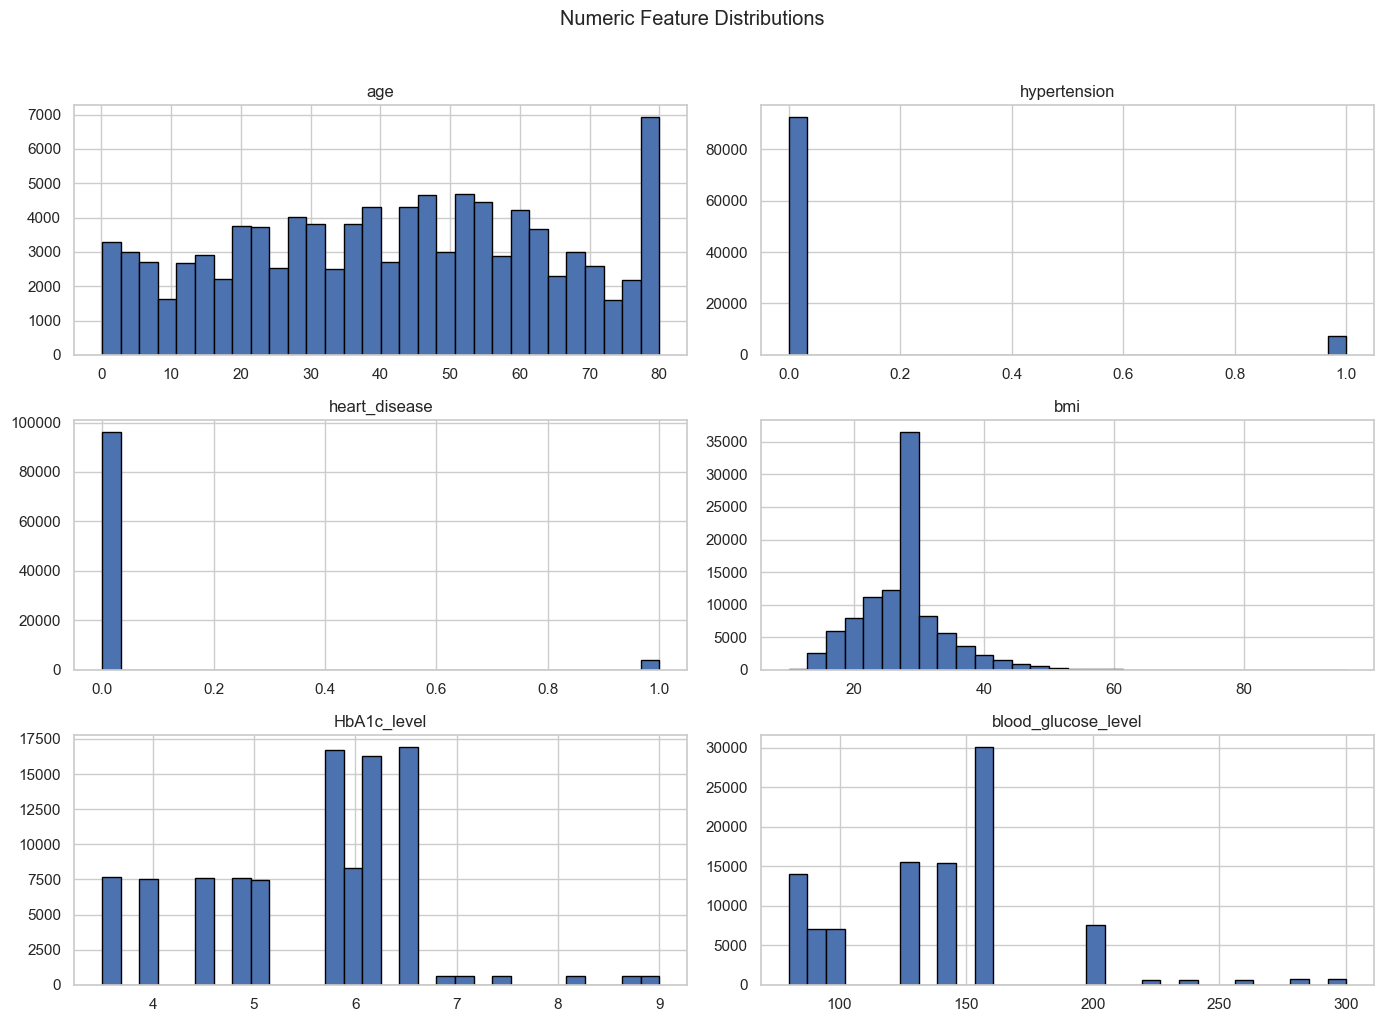

In [18]:
# CELL 9: Numeric Feature Distributions

numeric_columns = df.drop(columns=["diabetes"]).select_dtypes(
    include=np.number
).columns.tolist()

print("Numeric feature columns:", numeric_columns)

df[numeric_columns].hist(figsize=(14, 10), bins=30, edgecolor="black")
plt.suptitle("Numeric Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

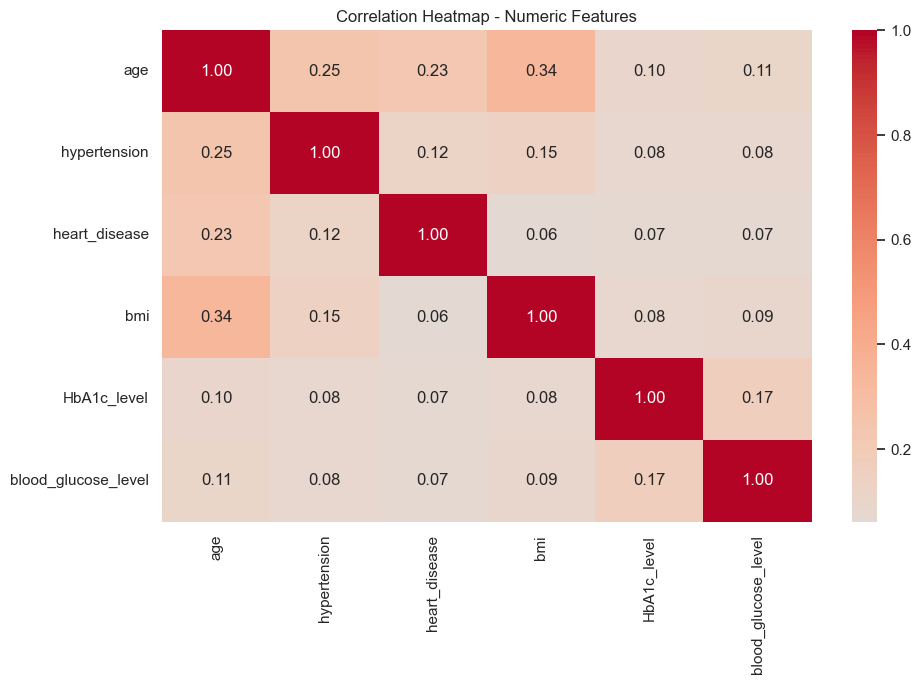

In [19]:
# CELL 10: Correlation Heatmap for Numeric Features

if len(numeric_columns) >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        df[numeric_columns].corr(),
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0
    )
    plt.title("Correlation Heatmap - Numeric Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation heatmap.")

### Observation - 2

Write down the main patterns you notice from the distributions and correlation heatmap. These plots describe the input features; they do not determine cluster labels.

---

# 3. Data Preprocessing

The target column is separated before preprocessing. Numeric features are median-imputed and standardized; categorical features are imputed with the most frequent value and one-hot encoded. The resulting feature matrix is used for all clustering algorithms.

In [20]:
# CELL 11: Separate Features and Ground-Truth Label

if "diabetes" not in df.columns:
    raise ValueError("Expected target column 'diabetes' was not found.")

y_true = df["diabetes"].copy()        # Reserved for post-hoc interpretation only
X_raw = df.drop(columns=["diabetes"]).copy()

numeric_features = X_raw.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X_raw.select_dtypes(exclude=["number", "bool"]).columns.tolist()

print("Feature matrix shape before preprocessing:", X_raw.shape)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target excluded from X:", "diabetes" not in X_raw.columns)

Feature matrix shape before preprocessing: (100000, 8)
Numeric features: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']
Categorical features: ['gender', 'smoking_history']
Target excluded from X: True


In [21]:
# CELL 12: Build Preprocessing Pipeline

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

transformers = []
if numeric_features:
    transformers.append(("numeric", numeric_pipeline, numeric_features))
if categorical_features:
    transformers.append(("categorical", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [22]:
# CELL 13: Transform Features

X_processed = preprocessor.fit_transform(X_raw)
feature_names = preprocessor.get_feature_names_out()
X_processed = np.asarray(X_processed, dtype=np.float32)

print("=" * 60)
print("PREPROCESSING COMPLETE")
print("=" * 60)
print("Processed matrix shape:", X_processed.shape)
print("Number of transformed features:", len(feature_names))
print("Contains only feature columns (no diabetes target):", "diabetes" not in list(X_raw.columns))

PREPROCESSING COMPLETE
Processed matrix shape: (100000, 15)
Number of transformed features: 15
Contains only feature columns (no diabetes target): True


### Observation - 3

Standardization is important for distance-based clustering because numeric features with large scales can otherwise dominate distances. One-hot encoding converts categorical values into numeric indicators.

---

# 4. K-Means Clustering

K-Means groups observations around cluster centroids. The Elbow Method examines how inertia changes as the number of clusters increases.

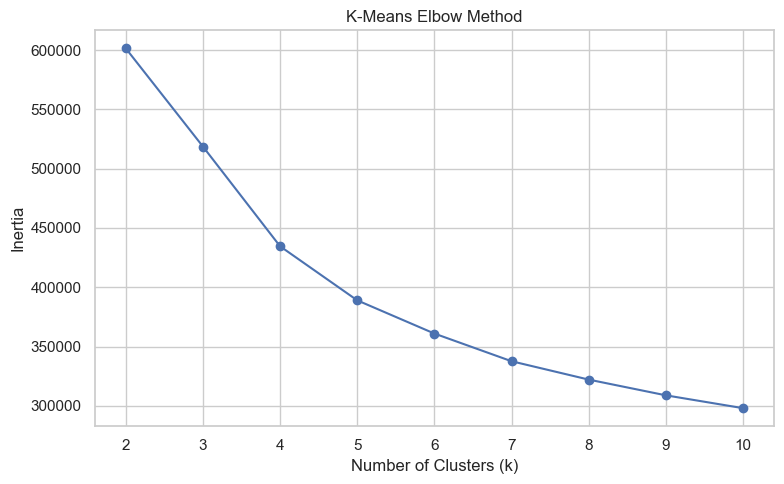

,k,Inertia
0,2,601528.62
1,3,518678.19
2,4,434536.19
3,5,388926.38
4,6,360912.44
5,7,337559.28
6,8,322069.03
7,9,308803.34
8,10,297976.53


In [23]:
# CELL 14: Elbow Method

MAX_K = 10
k_values = list(range(2, MAX_K + 1))
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_processed)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.tight_layout()
plt.show()

elbow_results = pd.DataFrame({"k": k_values, "Inertia": inertias})
display(elbow_results.round(2))

### 4.1 Select the number of clusters

Review the Elbow plot and choose a value for `BEST_K`. The default below is 3 as a starting point; change it if your plot supports a different choice. The elbow is a heuristic, not a guaranteed optimum.

In [24]:
# CELL 15: Fit K-Means

BEST_K = 3  # Change this after reviewing the Elbow plot

kmeans_model = KMeans(
    n_clusters=BEST_K,
    random_state=RANDOM_STATE,
    n_init=10
)
kmeans_labels = kmeans_model.fit_predict(X_processed)

print(f"K-Means fitted with k={BEST_K}.")
print("\nCluster sizes:")
display(pd.Series(kmeans_labels, name="Cluster").value_counts().sort_index().to_frame("Count"))

K-Means fitted with k=3.

Cluster sizes:


,Count
Cluster,
0,50566
1,45492
2,3942


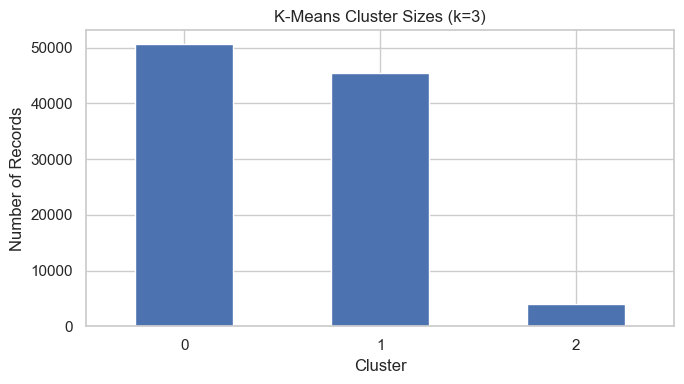

In [25]:
# CELL 16: K-Means Cluster Size Plot

cluster_counts = pd.Series(kmeans_labels).value_counts().sort_index()

plt.figure(figsize=(7, 4))
cluster_counts.plot(kind="bar")
plt.title(f"K-Means Cluster Sizes (k={BEST_K})")
plt.xlabel("Cluster")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation - 4

Record the chosen value of K and explain whether the Elbow plot has a clear bend or a gradual decline.

---

# 5. Clustering Evaluation Metrics

All clustering algorithms are evaluated using:
- **Silhouette Score:** higher values generally indicate better separation.
- **Davies–Bouldin Index:** lower values generally indicate more compact, separated clusters.
- **Calinski–Harabasz Index:** higher values generally indicate better-defined clusters.

For very large datasets, metrics are calculated on a reproducible sample to control computation time.

In [26]:
# CELL 17: Evaluation Function

def evaluate_clustering(X, labels, algorithm_name, sample_size=10000, random_state=RANDOM_STATE):
    labels = np.asarray(labels)
    unique_labels = np.unique(labels)

    if len(unique_labels) < 2 or len(unique_labels) >= len(labels):
        return {
            "Algorithm": algorithm_name,
            "Silhouette Score": np.nan,
            "Davies-Bouldin Index": np.nan,
            "Calinski-Harabasz Index": np.nan
        }

    if len(labels) > sample_size:
        rng = np.random.default_rng(random_state)
        indices = rng.choice(len(labels), size=sample_size, replace=False)
        X_eval = X[indices]
        labels_eval = labels[indices]
    else:
        X_eval = X
        labels_eval = labels

    if len(np.unique(labels_eval)) < 2:
        return {
            "Algorithm": algorithm_name,
            "Silhouette Score": np.nan,
            "Davies-Bouldin Index": np.nan,
            "Calinski-Harabasz Index": np.nan
        }

    return {
        "Algorithm": algorithm_name,
        "Silhouette Score": silhouette_score(X_eval, labels_eval),
        "Davies-Bouldin Index": davies_bouldin_score(X_eval, labels_eval),
        "Calinski-Harabasz Index": calinski_harabasz_score(X_eval, labels_eval)
    }

print("Evaluation function defined.")

Evaluation function defined.


In [27]:
# CELL 18: Evaluate K-Means

kmeans_metrics = evaluate_clustering(
    X_processed,
    kmeans_labels,
    f"K-Means (k={BEST_K})"
)

kmeans_metrics_df = pd.DataFrame([kmeans_metrics])
display(kmeans_metrics_df.round(4))

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means (k=3),0.1588,1.7414,2014.471802


### Observation - 5

Use all three metrics together rather than choosing a model from one metric alone. Silhouette values can be low for overlapping real-world data and should be interpreted in context.

# 6. Agglomerative Hierarchical Clustering

Agglomerative clustering repeatedly merges nearby clusters. It is more computationally expensive than K-Means for large datasets, so the hierarchical analysis below uses a reproducible subset. The subset size is reported for transparency.

In [28]:

HIERARCHICAL_MAX_ROWS = 2000
rng = np.random.default_rng(RANDOM_STATE)
hier_indices = rng.choice(
    len(X_processed),
    size=min(HIERARCHICAL_MAX_ROWS, len(X_processed)),
    replace=False
)

X_hier = X_processed[hier_indices]
y_hier = y_true.iloc[hier_indices].to_numpy()

print("Original dataset rows:", len(X_processed))
print("Rows used for hierarchical clustering:", len(X_hier))

Original dataset rows: 100000
Rows used for hierarchical clustering: 2000


### 6.1 Dendrogram

The dendrogram is computed on a smaller subset because hierarchical linkage requires substantial memory and time. The plot is truncated to show the final merges clearly.

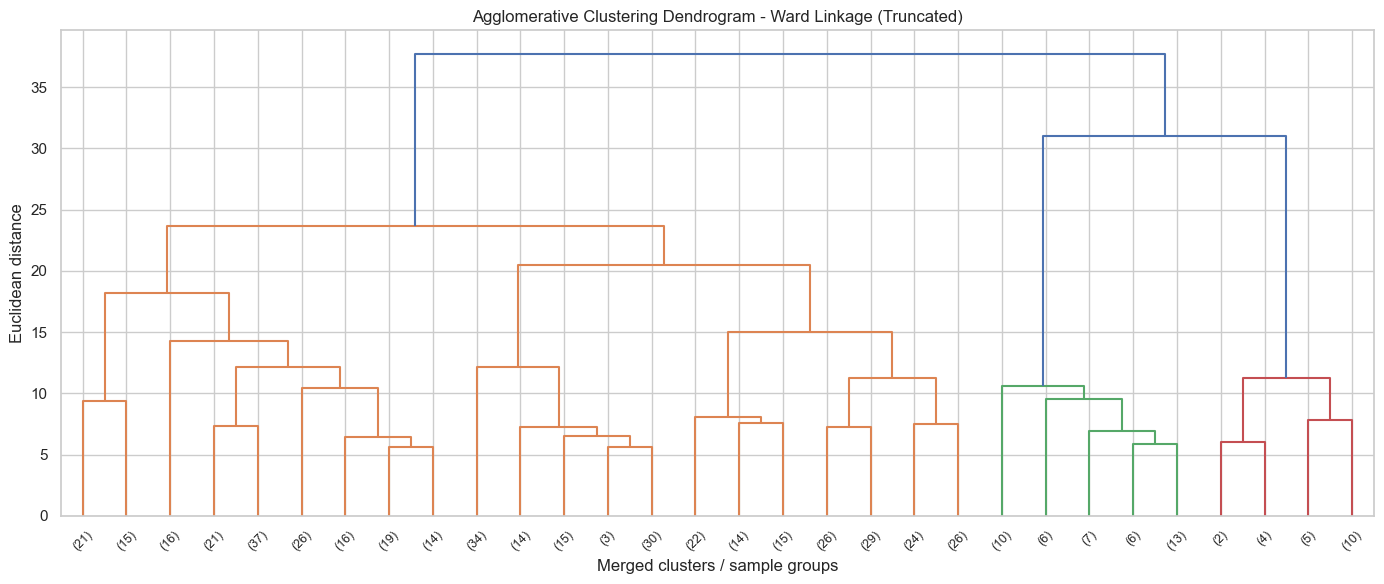

In [29]:
DENDROGRAM_MAX_ROWS = 500
dendro_indices = np.random.default_rng(RANDOM_STATE).choice(
    len(X_hier),
    size=min(DENDROGRAM_MAX_ROWS, len(X_hier)),
    replace=False
)

Z = linkage(X_hier[dendro_indices], method="ward", metric="euclidean")

plt.figure(figsize=(14, 6))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45,
    leaf_font_size=9
)
plt.title("Agglomerative Clustering Dendrogram - Ward Linkage (Truncated)")
plt.xlabel("Merged clusters / sample groups")
plt.ylabel("Euclidean distance")
plt.tight_layout()
plt.show()

### 6.2 Compare linkage strategies

We compare Ward, Complete, Average, and Single linkage on the same sample and with the same cluster count. Ward linkage is compatible with Euclidean distance and tends to create compact clusters.

In [30]:
linkage_methods = ["ward", "complete", "average", "single"]
agglomerative_labels = {}
agglomerative_metric_rows = []

for method in linkage_methods:
    model = AgglomerativeClustering(
        n_clusters=BEST_K,
        linkage=method,
        metric="euclidean"
    )
    labels = model.fit_predict(X_hier)
    agglomerative_labels[method] = labels

    result = evaluate_clustering(
        X_hier,
        labels,
        f"Agglomerative ({method})",
        sample_size=10000
    )
    agglomerative_metric_rows.append(result)

agglomerative_results = pd.DataFrame(agglomerative_metric_rows)
display(agglomerative_results.round(4))

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Agglomerative (ward),0.4056,1.0273,415.442505
1,Agglomerative (complete),0.4386,1.0785,195.278595
2,Agglomerative (average),0.4439,0.9388,190.764893
3,Agglomerative (single),0.4620,1.0419,188.339203


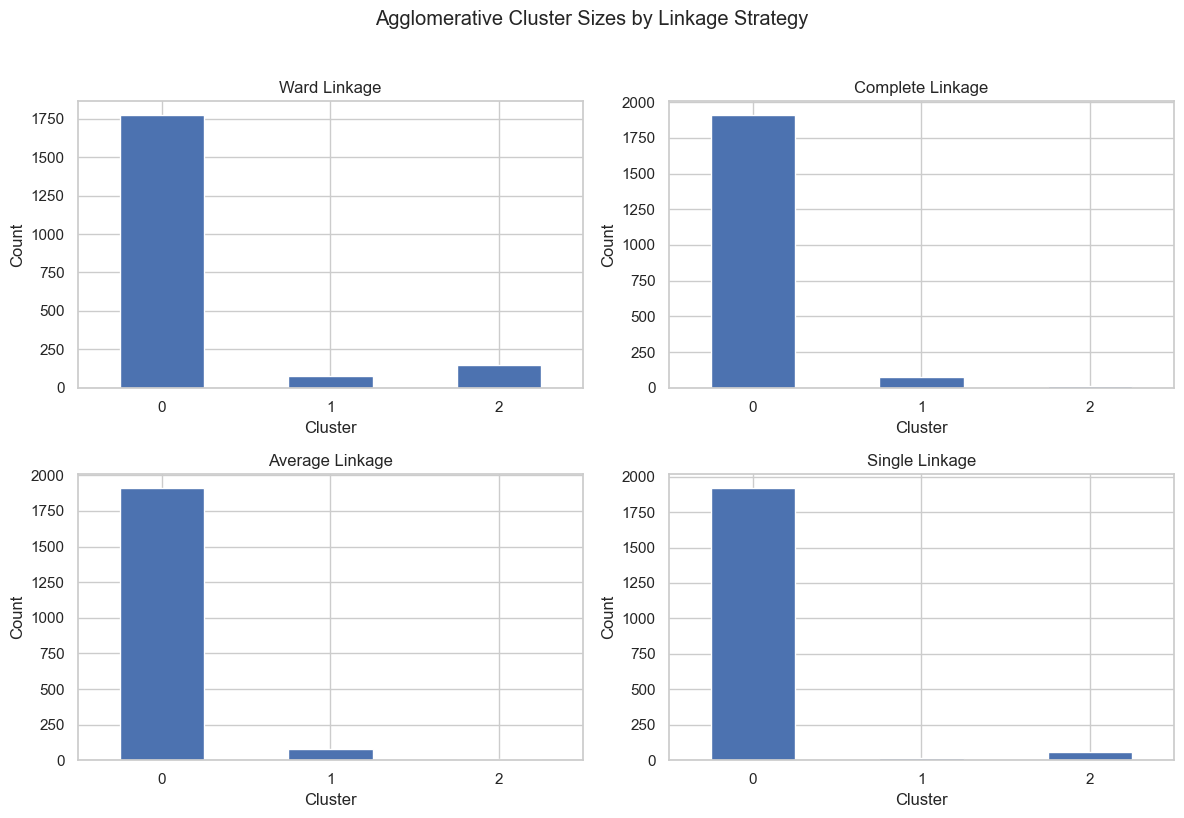

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, method in zip(axes.ravel(), linkage_methods):
    counts = pd.Series(agglomerative_labels[method]).value_counts().sort_index()
    counts.plot(kind="bar", ax=ax)
    ax.set_title(f"{method.title()} Linkage")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=0)

plt.suptitle("Agglomerative Cluster Sizes by Linkage Strategy", y=1.02)
plt.tight_layout()
plt.show()

### Observation - 6

Compare the linkage metric table and cluster-size plots. Single linkage can produce a chaining effect; Ward often favours compact clusters, but the metrics and data should guide the interpretation.


# 7. Compare Clustering Results

K-Means is fitted on the full processed dataset, while Agglomerative clustering is fitted on the reported subset. The metrics are useful for exploration, but this difference in sample size means the comparison is not perfectly like-for-like.

In [32]:

all_metrics = pd.concat(
    [
        pd.DataFrame([kmeans_metrics]),
        agglomerative_results
    ],
    ignore_index=True
)

display(all_metrics.round(4))

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means (k=3),0.1588,1.7414,2014.471802
1,Agglomerative (ward),0.4056,1.0273,415.442505
2,Agglomerative (complete),0.4386,1.0785,195.278595
3,Agglomerative (average),0.4439,0.9388,190.764893
4,Agglomerative (single),0.4620,1.0419,188.339203


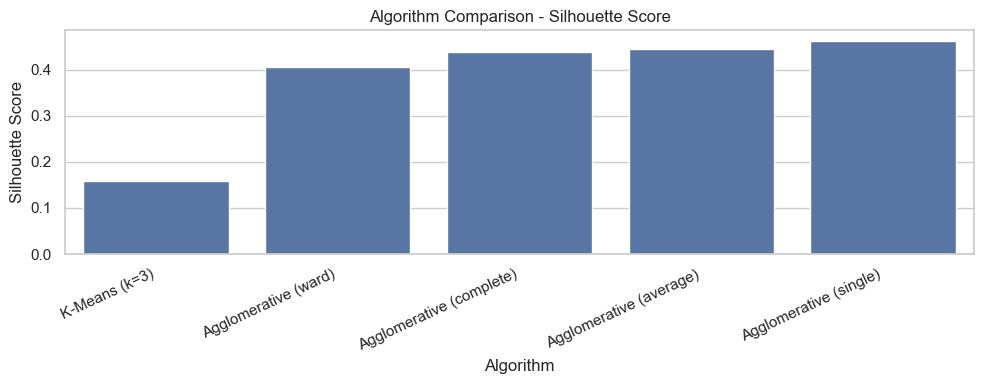

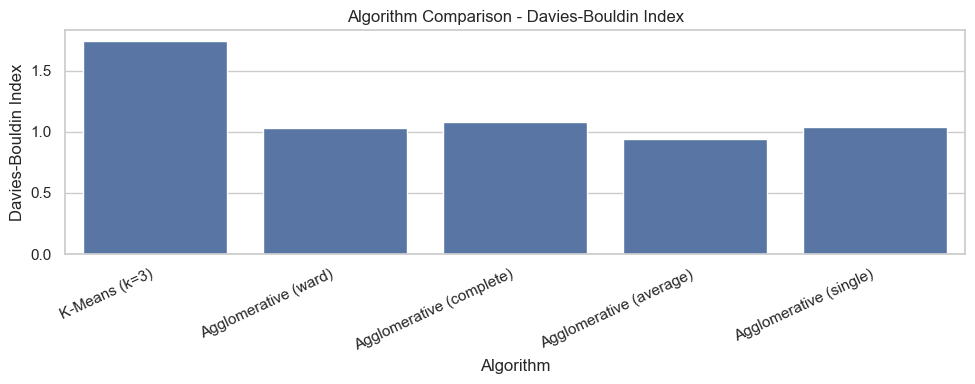

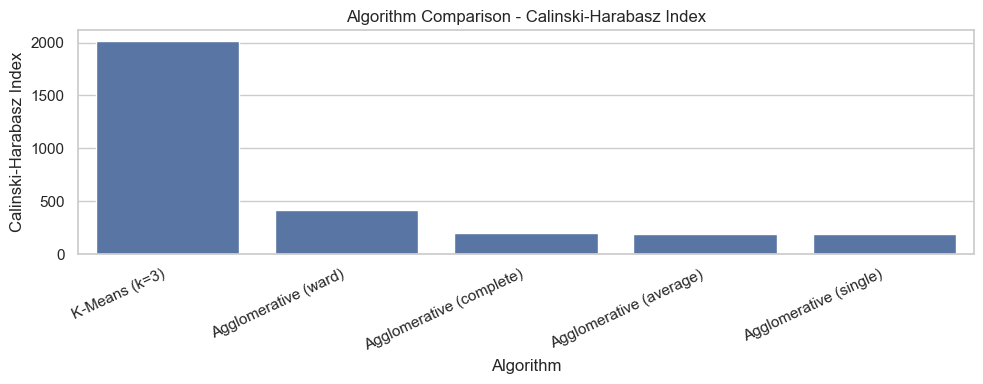

In [33]:
metric_columns = [
    "Silhouette Score",
    "Davies-Bouldin Index",
    "Calinski-Harabasz Index"
]

for metric in metric_columns:
    plt.figure(figsize=(10, 4))
    sns.barplot(data=all_metrics, x="Algorithm", y=metric)
    plt.title(f"Algorithm Comparison - {metric}")
    plt.xlabel("Algorithm")
    plt.ylabel(metric)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

### Observation - 7

Use the direction of each metric correctly: higher is preferred for Silhouette and Calinski–Harabasz, while lower is preferred for Davies–Bouldin. Also report the use of a sample for hierarchical clustering.


# 8. PCA Visualization

PCA reduces the processed feature matrix to two dimensions for visualization. The target column is not used to fit PCA. A sample is used for plotting so the notebook remains responsive.

In [34]:
# CELL 25: PCA for K-Means

PLOT_MAX_ROWS = 5000
plot_indices = np.random.default_rng(RANDOM_STATE).choice(
    len(X_processed),
    size=min(PLOT_MAX_ROWS, len(X_processed)),
    replace=False
)

X_plot = X_processed[plot_indices]
kmeans_plot_labels = kmeans_labels[plot_indices]

pca_model = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca_model.fit_transform(X_plot)

print("PCA explained variance ratio:", np.round(pca_model.explained_variance_ratio_, 4))
print("Total variance explained by two components:",
      round(pca_model.explained_variance_ratio_.sum(), 4))

PCA explained variance ratio: [0.2436 0.1482]
Total variance explained by two components: 0.3918


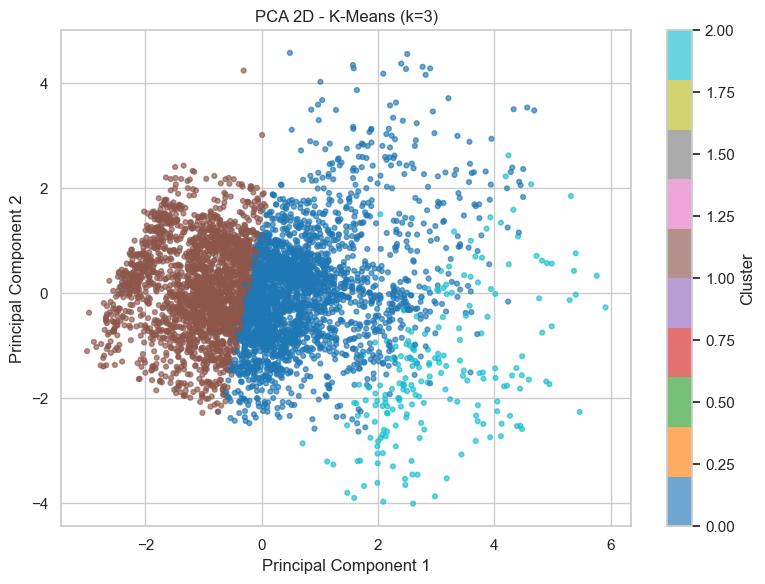

In [35]:
# CELL 26: K-Means PCA Scatter Plot

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=kmeans_plot_labels, s=12, alpha=0.65, cmap="tab10"
)
plt.title(f"PCA 2D - K-Means (k={BEST_K})")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

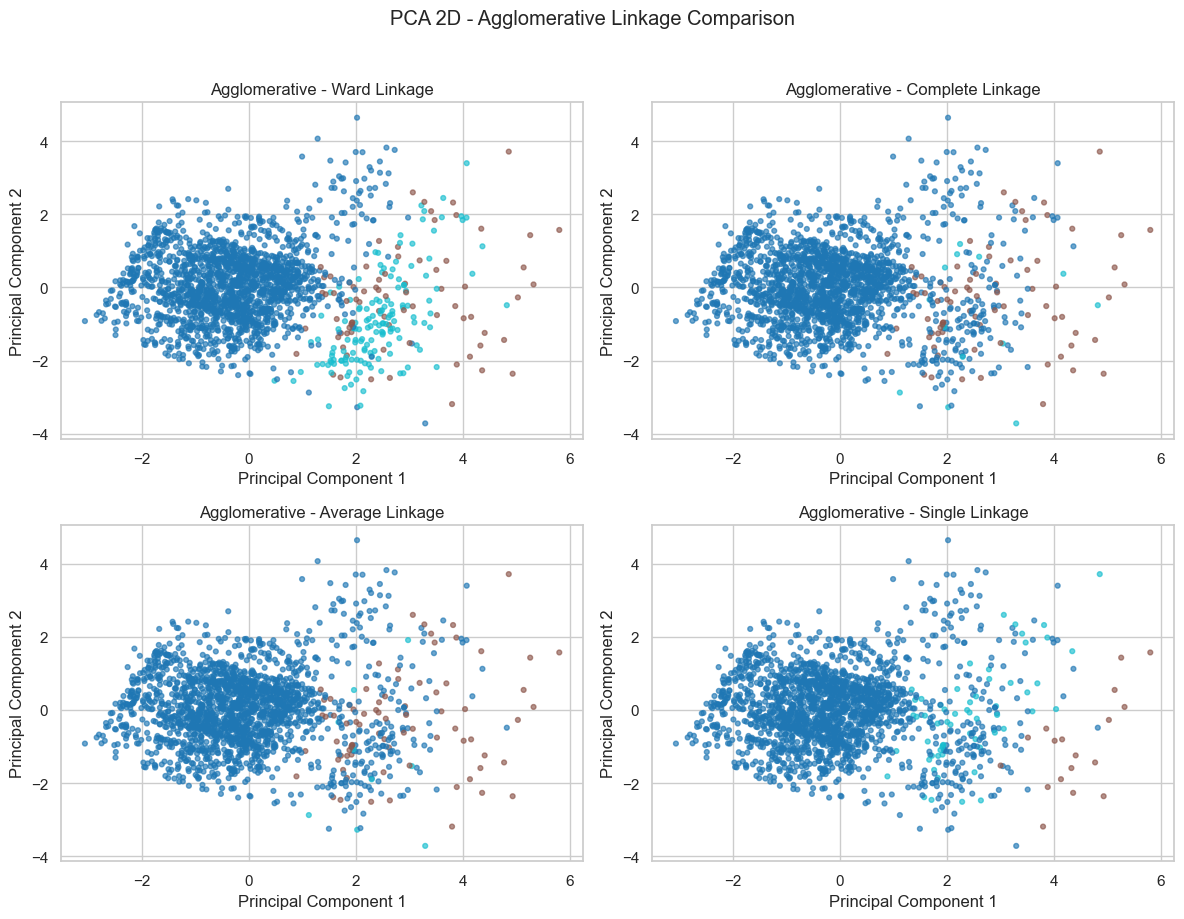

In [36]:
# CELL 27: PCA for Each Agglomerative Linkage

X_hier_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_hier)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, method in zip(axes.ravel(), linkage_methods):
    scatter = ax.scatter(
        X_hier_pca[:, 0], X_hier_pca[:, 1],
        c=agglomerative_labels[method],
        s=12, alpha=0.65, cmap="tab10"
    )
    ax.set_title(f"Agglomerative - {method.title()} Linkage")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.suptitle("PCA 2D - Agglomerative Linkage Comparison", y=1.02)
plt.tight_layout()
plt.show()

### Observation - 8

PCA plots show only two dimensions of the transformed feature space. Apparent overlap in the plot does not necessarily mean that clusters overlap in the full feature space.

# 9. t-SNE Visualization

t-SNE can reveal local neighbourhood structure in a 2D view. It is computationally expensive, so a smaller reproducible sample is used. t-SNE is only a visualization method here; clustering labels are generated by K-Means.

In [37]:
# CELL 28: Compute t-SNE Embedding

TSNE_MAX_ROWS = 2000
tsne_indices = np.random.default_rng(RANDOM_STATE).choice(
    len(X_processed),
    size=min(TSNE_MAX_ROWS, len(X_processed)),
    replace=False
)

X_tsne_input = X_processed[tsne_indices]
labels_tsne = kmeans_labels[tsne_indices]

tsne_model = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE
)
X_tsne = tsne_model.fit_transform(X_tsne_input)

print("t-SNE embedding shape:", X_tsne.shape)

t-SNE embedding shape: (2000, 2)


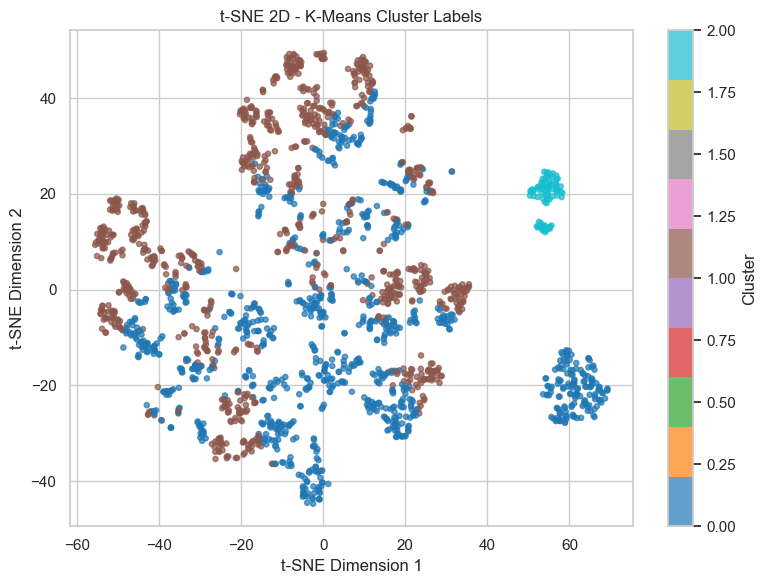

In [38]:
# CELL 29: t-SNE Plot for K-Means Clusters

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=labels_tsne, s=14, alpha=0.7, cmap="tab10"
)
plt.title("t-SNE 2D - K-Means Cluster Labels")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

### Observation - 9

t-SNE axes do not have direct feature meanings. Use the plot to discuss local visual groupings, not as a standalone numerical measure of clustering quality.


# 10. Post-Hoc Interpretation Using Ground-Truth Labels

This section is intentionally placed after all clustering fits. The `diabetes` label was not used in preprocessing, PCA, t-SNE, K-Means, or Agglomerative clustering. It is now used only to inspect the composition of the clusters.

In [39]:
kmeans_target_table = pd.crosstab(
    pd.Series(kmeans_labels, name="K-Means Cluster"),
    pd.Series(y_true.to_numpy(), name="diabetes"),
    normalize="index"
)

print("Row-wise proportions of ground-truth labels in each K-Means cluster:")
display(kmeans_target_table.round(3))

Row-wise proportions of ground-truth labels in each K-Means cluster:


diabetes,0,1
K-Means Cluster,,
0,0.861,0.139
1,0.995,0.005
2,0.679,0.321


In [40]:
# CELL 31: Post-Hoc External Validation for K-Means

kmeans_ari = adjusted_rand_score(y_true, kmeans_labels)
kmeans_nmi = normalized_mutual_info_score(y_true, kmeans_labels)

print("Post-hoc Adjusted Rand Index:", round(kmeans_ari, 4))
print("Post-hoc Normalized Mutual Information:", round(kmeans_nmi, 4))
print("\nThese scores compare clusters with labels after fitting; they were not used to train K-Means.")

Post-hoc Adjusted Rand Index: 0.0322
Post-hoc Normalized Mutual Information: 0.0866

These scores compare clusters with labels after fitting; they were not used to train K-Means.


In [41]:
# CELL 32: Post-Hoc External Validation for Agglomerative Linkages

posthoc_rows = []

for method, labels in agglomerative_labels.items():
    posthoc_rows.append({
        "Linkage": method,
        "Adjusted Rand Index (post-hoc)": adjusted_rand_score(y_hier, labels),
        "Normalized Mutual Information (post-hoc)": normalized_mutual_info_score(y_hier, labels)
    })

posthoc_results = pd.DataFrame(posthoc_rows)
display(posthoc_results.round(4))

,Linkage,Adjusted Rand Index (post-hoc),Normalized Mutual Information (post-hoc)
0,ward,0.2231,0.0694
1,complete,0.1910,0.0640
2,average,0.1667,0.0556
3,single,0.1718,0.0563


In [42]:
# CELL 33: Original Feature Profiles by K-Means Cluster

profile_df = X_raw.copy()
profile_df["cluster"] = kmeans_labels

numeric_profile_columns = profile_df.select_dtypes(include=np.number).columns.tolist()
if numeric_profile_columns:
    print("Mean numeric feature values by K-Means cluster:")
    display(profile_df.groupby("cluster")[numeric_profile_columns].mean().round(2))

for col in categorical_features:
    print(f"\n{col}: category proportions by K-Means cluster")
    display(pd.crosstab(
        profile_df["cluster"],
        profile_df[col],
        normalize="index"
    ).round(3))

Mean numeric feature values by K-Means cluster:


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,cluster
cluster,,,,,,,
0,56.81,0.13,0.0,30.41,5.72,145.07,0.0
1,23.05,0.00,0.0,23.71,5.28,129.04,1.0
2,67.82,0.23,1.0,29.33,5.88,152.14,2.0



gender: category proportions by K-Means cluster


gender,Female,Male,Other
cluster,,,
0,0.598,0.402,0.0
1,0.588,0.412,0.0
2,0.396,0.604,0.0



smoking_history: category proportions by K-Means cluster


smoking_history,No Info,current,ever,former,never,not current
cluster,,,,,,
0,0.244,0.103,0.049,0.138,0.390,0.076
1,0.495,0.080,0.027,0.033,0.314,0.050
2,0.234,0.104,0.079,0.230,0.278,0.074


### Observation - 10

Describe which feature profiles differ between clusters and how the ground-truth label is distributed across them. This is an exploratory analysis, not a clinical diagnosis or diabetes prediction model.

# 11. Final Summary

Complete the summary after running all cells. Use the actual output tables and plots rather than assuming one algorithm is best.

In [43]:
# CELL 34: Summary Table for Review Discussion

print("=" * 70)
print("CLUSTERING REVIEW SUMMARY")
print("=" * 70)
print(f"Dataset rows: {len(df):,}")
print(f"Original feature columns (excluding target): {X_raw.shape[1]}")
print(f"Transformed feature count: {X_processed.shape[1]}")
print(f"K-Means cluster count: {BEST_K}")
print(f"Rows used for Agglomerative clustering: {len(X_hier):,}")
print(f"Rows used for dendrogram: {len(dendro_indices):,}")
print(f"Rows used for t-SNE: {len(tsne_indices):,}")

display(all_metrics.round(4))
display(posthoc_results.round(4))

CLUSTERING REVIEW SUMMARY
Dataset rows: 100,000
Original feature columns (excluding target): 8
Transformed feature count: 15
K-Means cluster count: 3
Rows used for Agglomerative clustering: 2,000
Rows used for dendrogram: 500
Rows used for t-SNE: 2,000


,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means (k=3),0.1588,1.7414,2014.471802
1,Agglomerative (ward),0.4056,1.0273,415.442505
2,Agglomerative (complete),0.4386,1.0785,195.278595
3,Agglomerative (average),0.4439,0.9388,190.764893
4,Agglomerative (single),0.4620,1.0419,188.339203


,Linkage,Adjusted Rand Index (post-hoc),Normalized Mutual Information (post-hoc)
0,ward,0.2231,0.0694
1,complete,0.1910,0.0640
2,average,0.1667,0.0556
3,single,0.1718,0.0563
